In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV 
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X, y = make_classification(n_samples=1000, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_split=42)

rf = RandomForestClassifier(n_estimator=100, random_state=42)
search = GridSearchCV(GradientBoostingClassifier(n_estimators=300, n_iter_no_change=5, random_state=42), {"learning_rate": [0.1, 0.01, 0.02]}, cv=5, scoring="f1-macro", n_jobs=-1).fit(X_train, y_train)
gb = search.best_estimator_

models = {
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": rf,
    "Boosting": gb,
    "Stacking": StackingClassifier([("rf", rf), ("gb", gb)], final_estmator=LogisticRegression(), cv=5)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "accuracy: ", accuracy_score(y_test, pred), "macro-f1", f1_score(y_test, pred))

Bagging Acc 0.92
Random Forest Acc 0.905
Boosting Acc 0.895
Stacking Acc 0.895


/Users/orbin/miniconda3/envs/notebooks/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [ ]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

sigmoid = lambda z: 1 / (1 + np.exp(-z))

W1 = np.random.randn(2, 4)
W2 = np.random.randn(4, 1)
b1 = np.zeros((1, 4))
b2 = np.zeros((1, 1))

for _ in range(1000):
    h = sigmoid(X @ W1 + b1)
    pred = sigmoid(h @ W2 + b2)

    d2 = (pred - y) / len(X)
    dW2, db2 = h.T @ d2, d2.sum(axis=0, keepdims=True)
    d1 = (d2 @ W2.T) * h * (1-h)
    dW1, db1 = X.T @ d1 , d1.sum(axis=0, keepdims=True)

    W1 -= dW1
    b1 -= db1
    W2 -= dW2
    b2 -= db2

print((pred > 0.5).astype(int).ravel())

In [1]:
import tensorflow as tf 
from sklearn.datasets import load_iris 
from sklearn.model_selection import train_test_split  
from sklearn.preprocessing import StandardScaler

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y , test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])

model.compile(
    optimizer="Adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(X_train, y_train, epochs=100, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Accuracy: ", accuracy)

probabilities = model.predict(X_test[:1], verbose=0)
print("Predicted class: ", probabilities.argmax(axis=1)[0])

Accuracy:  0.9333333373069763
Predicted class:  1


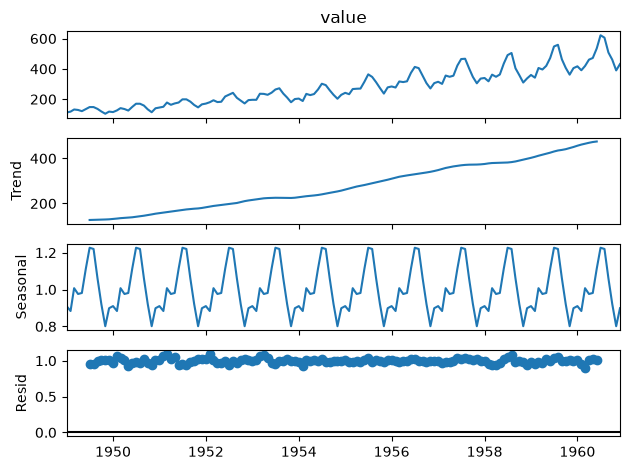

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt
import statsmodels.api as sm 
from statsmodels.tsa.seasonal import seasonal_decompose

series = sm.datasets.get_rdataset("AirPassengers").data["value"]
series.index = pd.date_range("1949-01-01", periods=len(series), freq="MS")

result = seasonal_decompose(series, model="multiplicative", period=12)
result.plot()
plt.tight_layout()
plt.show()

In [4]:
from statsmodels.tsa.stattools import adfuller 
import statsmodels.api as sm 

series = sm.datasets.get_rdataset("AirPassengers").data["value"]

diff = series.diff(12).diff()
p = adfuller(diff.dropna())[1]

print(f"p-value={p}")

p-value=1.8565116001234692e-28


/var/folders/xj/k0m7g06133vf7zhcrt6zz78h0000gn/T/ipykernel_89482/791132934.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p = adfuller(diff.dropna())[1]


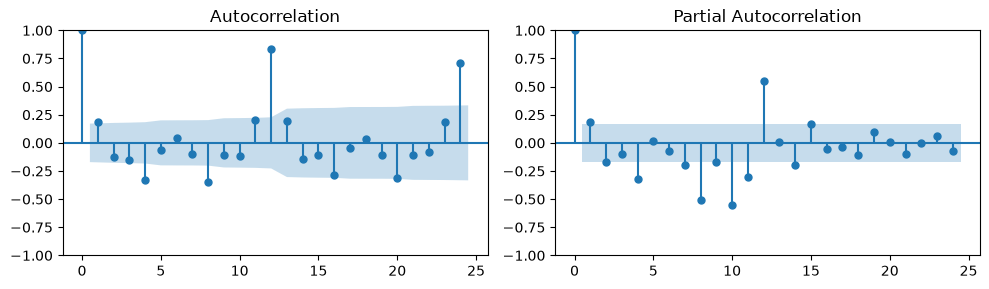

MSE: 0.0375


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf 
from statsmodels.tsa.arima.model import  ARIMA
from sklearn.metrics import mean_squared_error 

series = sm.datasets.get_rdataset("AirPassengers").data["value"]

y = np.log(series)

train, test = y.iloc[:-12], y.iloc[-12:]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(train.diff().dropna(), lags=24, ax=ax[0])
plot_pacf(train.diff().dropna(), lags=24, method="ywm", ax=ax[1])
plt.tight_layout()
plt.show()

model = ARIMA(train, order=(1, 1, 1))
fitted_model = model.fit()

forecast = fitted_model.forecast(steps=len(test))
mse = mean_squared_error(test, forecast)

print(f"MSE: {mse:.4f}")

/Users/orbin/miniconda3/envs/notebooks/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SARIMA RMSE: 16.90
Single RMSE: 102.98
Double RMSE: 85.56
Holt Winters RMSE: 28.69


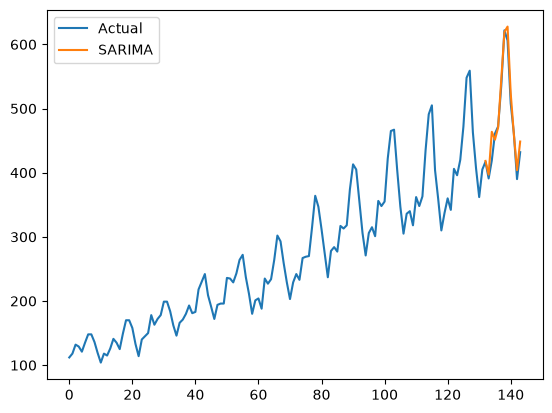

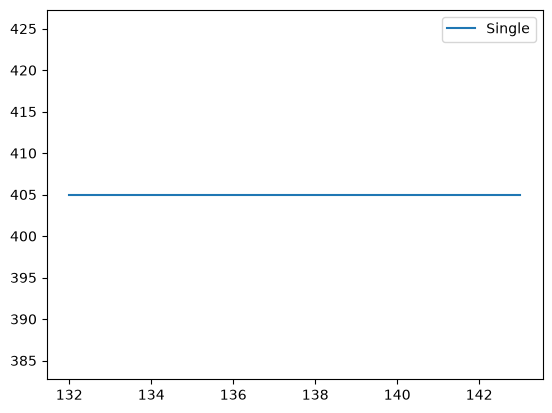

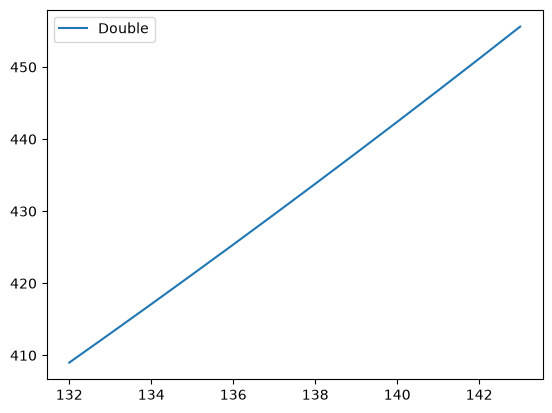

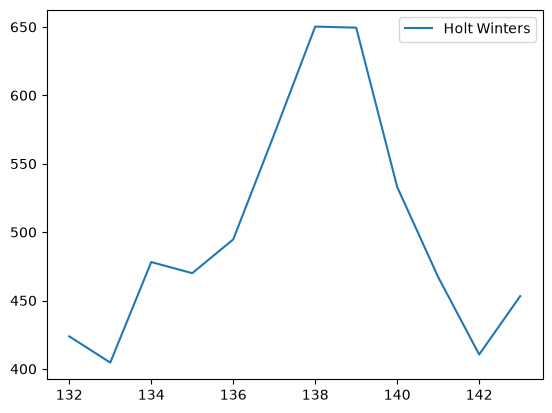

In [ ]:
import numpy as np
import matplotlit.pyplot as plt 
from statsmodels.tsa.statespace.sarimax import SARIMAX 
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from sklearn.metrics import mean_squared_error 

y = np.log(series)

train, test = y.iloc[:-12], y.iloc[-12:]

models = {
    "SARIMA": SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False),
    "Single": SimpleExpSmoothing(train, initialization_method="estimated").fit(),
    "Double": Holt(train, initialization_method="estimated").fit(),
    "Holt Winters": ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(),
}

forecasts = {name: model.forecast(12) for name, model in models.items()}

for name, forecast in forecasts.items():
    rmse = np.sqrt(mean_squared_error(np.exp(test), np.exp(forecast)))
    print(f"{name} RMSE: {rmse:.2f}")

plt.plot(series.index, series, label="Actual")
for name, forecast in forecasts.items():
    plt.plot(test.index, np.exp(forecast), label=name)
    plt.legend()
    plt.show()

19:48:30 - cmdstanpy - INFO - Chain [1] start processing
19:48:31 - cmdstanpy - INFO - Chain [1] done processing


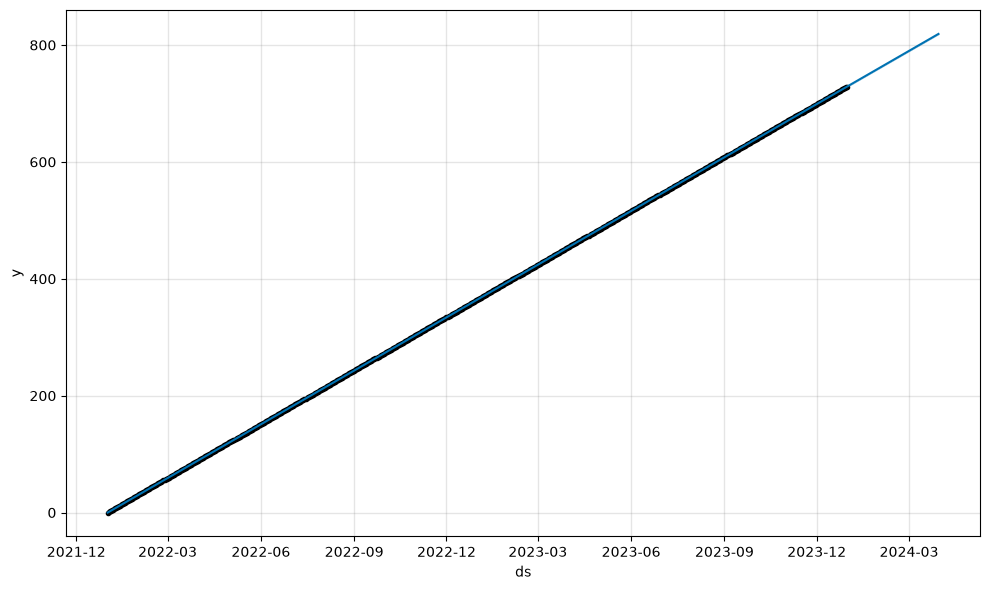

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt 
from prophet import Prophet 

df = pd.DataFrame({
    "ds": pd.date_range("2022-01-01", periods=730),
    "y":range(730)
})

model = Prophet()
model.fit(df)

future = model.make_future_dataframe(periods=90)
forecast = model.predict(future)

model.plot(forecast)
plt.show()

## Recurrent Neural Networks (RNNs)

### Questions

How do you build a simple RNN from scratch with NumPy?

In [ ]:
import numpy as np 

wx, wh, wy = 0.1, 0.1, 0.1
lr = 0.01

X = [1.0, 2.0, 3.0]
Y = [2.0, 3.0, 4.0]

# FP
H = [0.0]
Y_pred = []

for x in X:
    h = np.tanh(wx * x + wh * H[-1])
    H.append(h)
    Y_pred.append(wy * h)

# Backward Pass 
dwx = dwh = dwy = 0.0
dh_next = 0.0

for t in reversed(range(len(X))):
    dy = Y_pred[t] - Y[t]
    dwy += dy * H[t+1]

    dh = wy * dy + dh_next
    dh_raw = (1 - H[t+1] ** 2) * dh

    dwx += dh_raw * X[t]
    dwh += dh_raw * H[t]

    dh_next = wh * dh_raw 

wx -= lr * dwx 
wh -= lr * dwh
wy -= lr * dwy

print(Y_pred)

Predictions before update:  [np.float64(0.009966799462495582), np.float64(0.020693472112300316), np.float64(0.031013382783067464)]


In [11]:
import tensorflow as tf 

X = tf.constant([[[1.0], [2.0], [3.0]]])
Y = tf.constant([[[2.0], [3.0], [4.0]]])

for layer in [tf.keras.layers.LSTM, tf.keras.layers.GRU]:
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(3, 1)),
        layer(1, return_sequences=True),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse")
    model.fit(X, Y, epochs=200, verbose=0)

    print(layer.__name__, model.predict(X, verbose=0).ravel())

LSTM [0.42711395 0.91904694 1.466186  ]
GRU [0.45519376 0.66868114 0.80407846]


## Convolutional Neural Networks (CNNs)

### Questions

How do you build and evaluate a CNN for image classification?

In [12]:
import tensorflow as tf 
from tensorflow.keras import layers 

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1)/255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0

model = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)), 
    layers.Conv2D(8, 3, activation="relu"),
    layers.MaxPool2D(2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=3)

loss, accuracy = model.evaluate(x_test, y_test)

print("accuracy", accuracy)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9069 - loss: 0.3259
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9561 - loss: 0.1557
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9693 - loss: 0.1107
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9733 - loss: 0.0911  
accuracy 0.9732999801635742


## OpenCV

### Questions

How do you read, preprocess, augment, annotate, and display an image with OpenCV?

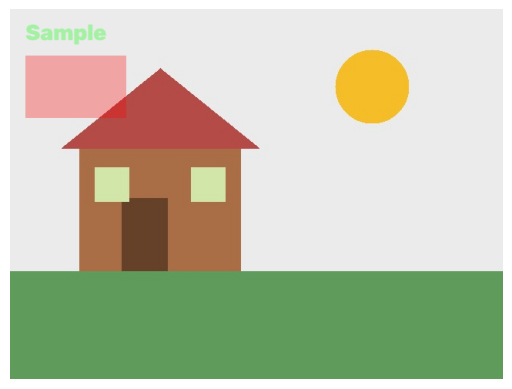

In [15]:
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 

img = cv2.imread("/Users/orbin/Documents/GitHub/Machine_Learning/BOARDING_MOD_2/TEST/TEST_4/img.jpg")

h, w = img.shape[:2]

resized = cv2.resize(img, (256, 256))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
normalized = resized.astype(np.float32) / 255.0

flipped = cv2.flip(img, 1)
M = cv2.getRotationMatrix2D((w/2, h/2), 15, 1.0)
rotated = cv2.warpAffine(img, M, (w, h))

adjusted = cv2.convertScaleAbs(img, alpha=1.2, beta=20)

overlay = img.copy()
cv2.putText(overlay, "Sample", (20, 40), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 255, 0), 2)
cv2.rectangle(overlay, (20, 60), (150, 140), (0, 0, 255), -1)
marked = cv2.addWeighted(overlay, 0.3, img, 0.7, 0)

plt.imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Generative Models

### Questions

#### 1. Implement a Variational Autoencoder with TensorFlow/Keras.


In [16]:
import tensorflow as tf 
from tensorflow.keras import layers 

encoder = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(2)
])

decoder = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(0.01)

X = tf.constant([[0.0], [0.2], [0.8], [1.0]])

for step in range(1000):
    with tf.GradientTape() as tape:
        mean, log_var = tf.split(encoder(X), 2, axis=1)
        noise = tf.random.normal(tf.shape(mean)) 
        z = mean + tf.exp(0.5 * log_var) * noise 

        reconstruction = decoder(z)

        reconstruction_loss = tf.reduce_mean(
            tf.square(X - reconstruction)
        )

        kl_loss = -0.5 * tf.reduce_mean(
            1 + log_var - mean**2 - tf.exp(log_var)
        )

        loss = reconstruction_loss + kl_loss 

        weights = encoder.trainable_variables + decoder.trainable_variables
        gradients = tape.gradient(loss, weights)
        optimizer.apply_gradients(zip(gradients, weights))

print(decoder(tf.random.normal((5, 1))).numpy())

[[0.5426245 ]
 [0.52929795]
 [0.49209437]
 [0.45948845]
 [0.4749508 ]]


#### 2. How do you build a simple GAN with TensorFlow/Keras?

In [19]:
import tensorflow as tf
from tensorflow.keras import layers 

G = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1)
])

D = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1, activation="sigmoid")
])

loss = tf.keras.losses.BinaryCrossentropy()
g_opt = tf.keras.optimizers.Adam(0.01)
d_opt = tf.keras.optimizers.Adam(0.01)

real = tf.ones((16,1))
ones = tf.ones((16, 1))
zeros = tf.zeros((16, 1))

for step in range(1000):
    noise = tf.random.normal((16, 1))

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = G(noise)

        real_pred = D(real)
        fake_pred = D(fake)

        g_loss = loss(ones,fake_pred)

        d_loss = loss(ones, real_pred) + loss(zeros, fake_pred)

    g_grads = gt.gradient(g_loss, G.trainable_variables)
    d_grads = dt.gradient(d_loss, D.trainable_variables)

    g_opt.apply_gradients(zip(g_grads, G.trainable_variables))
    d_opt.apply_gradients(zip(d_grads, D.trainable_variables))

print("Generated numbers: ")
print(G(tf.random.normal((5, 1))).numpy())

Generated numbers: 
[[2.229414 ]
 [2.2167692]
 [2.2194507]
 [2.2270842]
 [2.2146819]]


## Attention and Transformer Models

### Questions

How do you implement a Transformer block with multi-head self-attention?

In [ ]:
import tensorflow as tf 
from tensorflow.keras import layers 

class TransformerBlock(layers.Layer):
    def __init__(self, d_model, num_heads):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads = num_heads,
            key_dim=d_model//num_heads
        )

        self.feed_forward = tf.keras.Sequential([
            layers.Dense(d_model, activation="relu"),
            layers.Dense(d_model)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()

    def call(self, x):
        attended = self.attention(x, x)
        x = self.norm1(x+attended)

        fed = self.feed_forward(x)
        return self.norm2(x+fed)

X = tf.random.normal((1, 3, 4))

block = TransformerBlock(d_model=4, num_heads=2)
output = block(X)

print(output.shape)

### Questions

How do you fine-tune BERT for text classification?

In [ ]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer)

name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

tokens = tokenizer(
    ["Great Product!", "Terrible experience."],
    padding=True,
    truncation=True,
)

data = Dataset.from_dict({
    **tokens,
    "labels": [1, 0],
})

model = AutoModelForSequenceClassification.from_pretrained(
    name, num_labels=2
)

trainer = Trainer(
    model=model,
    args=TrainingArguments(
        output_dir="bert-results",
        num_train_epochs=3,
        report_to="none"
    ),
    train_dataset=data
)

trainer.train()

## Natural Language Processing (NLP)

Given the following text:
```
text = (
    "I can't believe how good this movie was! "
    "The actors were running everywhere. "
    "Apple opened an office in London. "
    "Cats and dogs love playing outside."
)
```

Perform these tasks:
1. Clean the text: expand contractions, lowercase, remove punctuation, correct spelling, and remove stopwords.
2. Apply Porter and Snowball stemming.
3. Apply lemmatization and display POS tags.
4. Extract named entities.
5. Build TF-IDF vectors and calculate cosine similarity between two sentences.
6. Train CBOW and Skip-gram Word2Vec models.
7. Analyze sentiment using VADER and TextBlob.
8. Discover two topics using LDA.
Answer
Treat each sentence as a document for TF-IDF, Word2Vec, and LDA.

In [ ]:
import re
import nltk
import spacy
import contractions

from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer 
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity 
from gensim.models import Word2Vec, LdaModel
from gensim.corpora import Dictionary 
nltk.download("stopwords")
nltk.download("vader_lexicon")

nlp = spacy.load("en_core_web_sm")

text = (
    "I can't believe how good this movie was! "
    "The actors were running everywhere. "
    "Apple opened an office in London. "
    "Cats and dogs love playing outside."
)

stop_words = set(stopwords.words("english"))

def clean(text):
    text = contractions.fix(text).lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = str(TextBlob(text).correct())
    return [w for w in text.split() if w not in stopwords]

words = clean(text)
print("Cleaned: ", words)

porter = PorterStemmer()
snowball = SnowballStemmer()

print("Porter: ",[porter.stem(w) for w in words])
print("Snowball: ", [snowball.stem(w) for w in words])

doc = nlp(text)

for token in doc:
    if token.is_alpha:
        print(token.text, token.lemma_, token.pos_)

for entity in doc.ents:
    print(entity.text, entity.label_)

sentences = [clean(sentence.text) for sentence in doc.sents]
documents = [" ".join(sentence) for sentence in sentences]

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(documents)

print("Vocabulary: ", tfidf.get_feature_names_out())
print("TF-IDF: ", matrix.toarray())
print("Similarity: ", cosine_similarity(matrix[0], matrix[1])[0, 0])

cbow = Word2Vec(sentences, vector_size=20, min_count=1, sg=0)
skipgram = Word2Vec(sentences, vector_size=20, min_count=1, sg=1)

print("CBOW: ", cbow.wv["movie"])
print("Skip-gram", skipgram.wv["movie"])

# SA
vader = SentimentIntensityAnalyzer()

print("VADER: ", vader.polarity_scores(text))
print("TextBlob: ", TextBlob(text).sentiment.polarity)

dictionary = Dictionary(sentences)
corpus = [dictionary.doc2bow(sentence) for sentence in sentences]

lda = LdaModel(
    corpus,
    id2word=dictionary,
    num_topics=2,
    passes=10,
    random_state=42
)

print("Topics: ", lda.print_topics())

## Big Data

### Questions

How do you implement a MapReduce word count with a mapper and reducer?

In [ ]:
import re 
from collections import Counter

text = "Hello hello world"

mapped = [(word, 1) for word in re.findall(r"\w+", text.lower())]

counts = Counter()
for word, count in mapped:
    counts[word] += count

print(counts)

### Questions

Task: Apache Spark Sales Analysis

Create a PySpark DataFrame with columns `order_id`, `region`, `product`, `quantity`, and `unit_price`.

1. Calculate `total_amount` as `quantity × unit_price` using `withColumn()`.
2. Filter orders where `total_amount > 5000`.
3. Group the data by `region` and calculate total sales and order count.
4. Sort regions by total sales in descending order.
5. Display the top two regions using Spark DataFrame operations.

Constraint: Use PySpark transformations and actions without converting the DataFrame to Pandas.

In [ ]:
from pyspark.sql import SparkSession 

spark = SparkSession.builder.appName("SaleAnalysis").getOrCreate()

data = [
    (101, "South", "Laptop", 2, 45000),
    (102, "North", "Mobile", 5, 15000),
    (103, "South", "Tablet", 3, 20000),
    (104, "East", "Laptop", 1, 50000),
    (105, "West", "Mobile", 4, 12000),
    (106, "North", "Laptop", 2, 55000),
    (107, "East", "Tablet", 5, 10000),
    (108, "West", "Laptop", 1, 60000),
    (109, "South", "Mobile", 6, 10000),
    (110, "North", "Tablet", 4, 18000)
]

columns = ["order_id", "region", "product", "quantity", "unit_price"]

df = spark.createDataFrame(data, columns)

df.show()

In [ ]:
from pyspark.sql import functions as F 

df = df.withColumn("total_amount", df.quantity * df.unit_price)
df = df.filter(df.total_amount>5000)

result = df.groupBy("region").agg(
    F.sum("total_amount").alias("total_sales"),
    F.count("*").alias("order_count")
)

result.orderBy(F.desc("total_sales")).show(2)

### Questions

Tasks to Complete

1.⁠ ⁠Extract
	•	Read both CSV files using Spark.
	•	Infer schema and verify row counts.

2.⁠ ⁠Transform
	•	Drop columns with more than 50% missing values.
	•	Fill missing numerical values with median.
	•	Encode Sex as numeric.
	•	Join train.csv with gender_submission.csv on PassengerId.
	•	Assemble features using VectorAssembler.
	•	Standardize features.

3.⁠ ⁠Load
	•	Write the transformed dataset to disk in Parquet format.

4.⁠ ⁠ETL Pipeline
	•	Combine extract, transform, and load steps into one Spark pipeline/script.
	•	Ensure it runs end-to-end.

5.⁠ ⁠Machine Learning
	•	Split data into train/test.
	•	Train one classification model using Spark MLlib.
	•	Generate predictions on test data.

6.⁠ ⁠Evaluation
	•	Compute accuracy and F1-score.

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression 
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

spark = SparkSession.builder.appName("Practice").getOrCreate()

# Extract
df = spark.read.csv("train.csv", header=True, inferSchema=True)
gender = spark.read.csv("gender_submission.csv", header=True, inferSchema=True)

df.printSchema()
gender.printSchema()

n = df.count()
print(n, gender.count())

# Clean
for c in df.columns:
    if df.filter(F.col(c).isNull()).count() > n / 2:
        df = df.drop(c)

df = df.withColumn(
    "Sex", F.when(F.col("Sex") == "male", 0.0).otherwise(1.0)
)

# Join
df = df.join(gender, "PassengerId", "left")

cols = ["Age", "Sex"]
filled = [c + "_filled" for c in cols]

train, test = df.randomSplit([0.8, 0.2], seed=42)

pipeline = Pipeline(stages=[
    Imputer(strategy="median", inputCols=cols, outputCols=filled),
    VectorAssembler(inputCols=filled, outputCol="vector"),
    StandardScaler(inputCol="vector", outputCol="features", withMean=True),
    LogisticRegression(labelCol="Survived", maxIter=10),
])

model = pipeline.fit(train)

model.transform(df).write.mode("overwrite").parquet("output")

predictions = model.transform(test)
predictions.select("Survived", "prediction").show()

evaluator = MulticlassClassificationEvaluator(labelCol="Survived")

for metric in ["accuracy", "f1"]:
    print(metric, evaluator.evaluate(predictions, {evaluator.metricName: metric}))

### 2. Spark SQL: Filter and Group

**Question:** Using the same passenger DataFrame, display passengers older than 30 and calculate passenger count and average age for each sex.

In [ ]:
df.createOrReplaceTempView("passengers")

spark.sql("""
    SELECT Age, Sex
    FROM passengers
    WHERE Age > 30
    ORDER BY Age DESC
""").show()

spark.sql("""
    SELECT Sex, Count(*) AS total, AVG(Age) AS average_age
    FROM passengers
    GROUP BY Sex
""").show()

### 3. Spark RDD: Filter, Map, and Reduce

**Question:** Extract error logs and count messages for each log level.

In [ ]:
logs = ["ERROR crash", "INFO started", "ERROR timeout"]

rdd = spark.sparkContext.parallelize(logs)

print(rdd.filter(lambda x: x.startswith("ERROR")).collect())

counts = (
    rdd.map(lambda x: (x.split()[0], 1)).reduceByKey(lambda a, b: a + b)
)

print(counts.collect())

spark.stop()

In [ ]:
mkdir iris-project
cd iris-project

python3.11 -m venv .venv
source .venv/bin/activate

git init

In [ ]:
# requirements.txt
scikit-learn
mlflow==2.22.0
joblib
fastapi
uvicorn
pytest
httpx
dvc

In [ ]:
pip install -r requirements.txt
dvc init

In [ ]:
# .gitignore
.venv/
mlruns/
__pycache__/
.pytest_cache/

In [ ]:
# train.py
import joblib
import mlflow.sklearn
from sklearn.datasets import load_iris 
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

with mlflow.start_run():
    model = DecisionTreeClassifier(max_depth=3)
    model.fit(X_train, y_train)

    mlflow.log_param("max_depth", 3)
    mlflow.log_metric("accuracy", model.score(X_test, y_test))
    mlflow.sklearn.log_model(model, "model")

    joblib.dump(model, "model.pkl")

In [ ]:
python train.py

In [ ]:
mlflow ui

In [ ]:
# main.py

import joblib 
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()
model = joblib.load("model.pkl")

class IrisInput(BaseModel):
    features: list[float]

@app.post("/predict")
def predict(data: IrisInput):
    result = model.predict([data.features])
    return {"prediction": int(result[0])}


In [ ]:
uvicorn main:app --reload

In [ ]:
dvc add model.pkl

In [ ]:
mkdir -p ../dvc-storage
dvc remote add --local -d storage "$PWD/../dvc-storage"
dvc push

In [ ]:
git add .
git commit -m "add iris project"

git branch -M main
git remote add origin https://github.com/YOUR_USERNAME/iris-project.git
git push -u origin main

In [ ]:
# test_main.py
from main import predict, IrisInput

def test_predict():
     data = IrisInput(features=[5.1, 3.5, 1.4, 0.2])
     assert predict(data) == {"prediction": 0}

In [ ]:
python -m pytest -v

In [ ]:
mkdir -p .github/workflows

In [ ]:
# ci.yml 
name: Test

on: [push]

jobs:
    test:
        runs-on: ubuntu-latest

        steps:
            - uses: actions/checkout@v6

            - uses: actions/setup-python@v6
              with:
                python-version: "3.11"

            - run: pip install -r requirements.txt
            - run: python train.py
            - run: python -m pytest -v

In [ ]:
git add .
git commit -m "add prediction test and ci"
git push

In [ ]:
# Dockerfile
FROM python:3.11-slim
WORDDIR /app
COPY requirements.txt
RUN pip install -r requirements.txt
COPY main.py model.pkl ./
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]

In [ ]:
docker build -t iris-api .
docker run --rm -p 8000:8000 iris-api

In [ ]:
import os
import json
import joblib

def model_fn(model_dir):
    return joblib.load(os.path.join(model_dir, "model.joblib"))

def input_fn(body, content_type):
    return json.loads(body)

def predict_fn(data, model):
    return str(model.predict([data["features"]])[0])

def output_fn(prediction, accept):
    return json.dumps({"prediction": prediction})

In [ ]:
import tarfile
import sagemaker 
from sagemaker.sklearn.model import SKLearnModel

session = sagemaker.Session()

with tarfile.open("model.tar.gz", "w:gz") as archive:
    archive.add("model.joblib")

model = SKLearnModel(
    model_data = session.upload_data("model.tar.gz"),
    role="ARN_code",
    entry_point="inference.py",
    framework_version="1.4-2"
)

predictor = model.deploy(
    initial_instance_count=1,
    instance_type="ml.m5.large"
)